###  ML Experiment Number 9
Student Name : Pranay Mestry

Batch : CS2


Roll Number : CS31



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
# Task 1: Import Libraries and Upload Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Upload CSV file
uploaded = files.upload()

# Load uploaded dataset
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# Display dataset
print("Dataset loaded successfully!")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Saving palmerpenguins_extended.csv to palmerpenguins_extended.csv
Saving palmerpenguins_original.csv to palmerpenguins_original.csv
Dataset loaded successfully!
  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  

Dataset Shape: (3430, 11)

Column

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:
# Task 2: Select Features and Target & Preprocess

from sklearn.preprocessing import LabelEncoder

# Handle different column names in the dataset
if "culmen_length_mm" in df.columns:
    length_col = "culmen_length_mm"
    depth_col = "culmen_depth_mm"
else:
    length_col = "bill_length_mm"
    depth_col = "bill_depth_mm"

# Select features and target
features = [length_col, depth_col, "flipper_length_mm", "body_mass_g"]
target = "species"

# Handle missing values
df = df.dropna(subset=features + [target]).copy()

X = df[features]
y = df[target]

# Encode categorical target labels
le = LabelEncoder()
y = le.fit_transform(y)

# Display results
print("Selected Features:", features)
print("Target: species")
print("\nSpecies Encoding:", dict(zip(le.classes_, le.transform(le.classes_))))

Selected Features: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Target: species

Species Encoding: {'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
# Task 3: Split the Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (2744, 4)
Testing data shape: (686, 4)
Training target shape: (2744,)
Testing target shape: (686,)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
# Task 4: Implement CART Classifier

from sklearn.tree import DecisionTreeClassifier

# Create CART classifier using Gini criterion
cart_model = DecisionTreeClassifier(criterion="gini", random_state=42)

# Train the model
cart_model.fit(X_train, y_train)

# Make predictions on test data
y_pred = cart_model.predict(X_test)

print("CART Classifier implemented successfully!")
print("Actual Labels:   ", y_test[:10])
print("Predicted Labels:", y_pred[:10])

CART Classifier implemented successfully!
Actual Labels:    [0 2 0 0 0 2 1 0 2 0]
Predicted Labels: [2 2 0 0 2 2 1 0 0 0]


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Model Accuracy: 0.4518950437317784

Confusion Matrix:
 [[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]


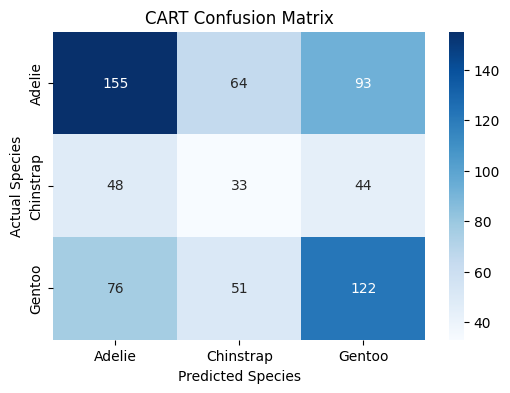


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



In [ ]:
# Task 5: Evaluate CART Model

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("CART Model Accuracy:", accuracy)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("CART Confusion Matrix")
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=le.classes_
))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


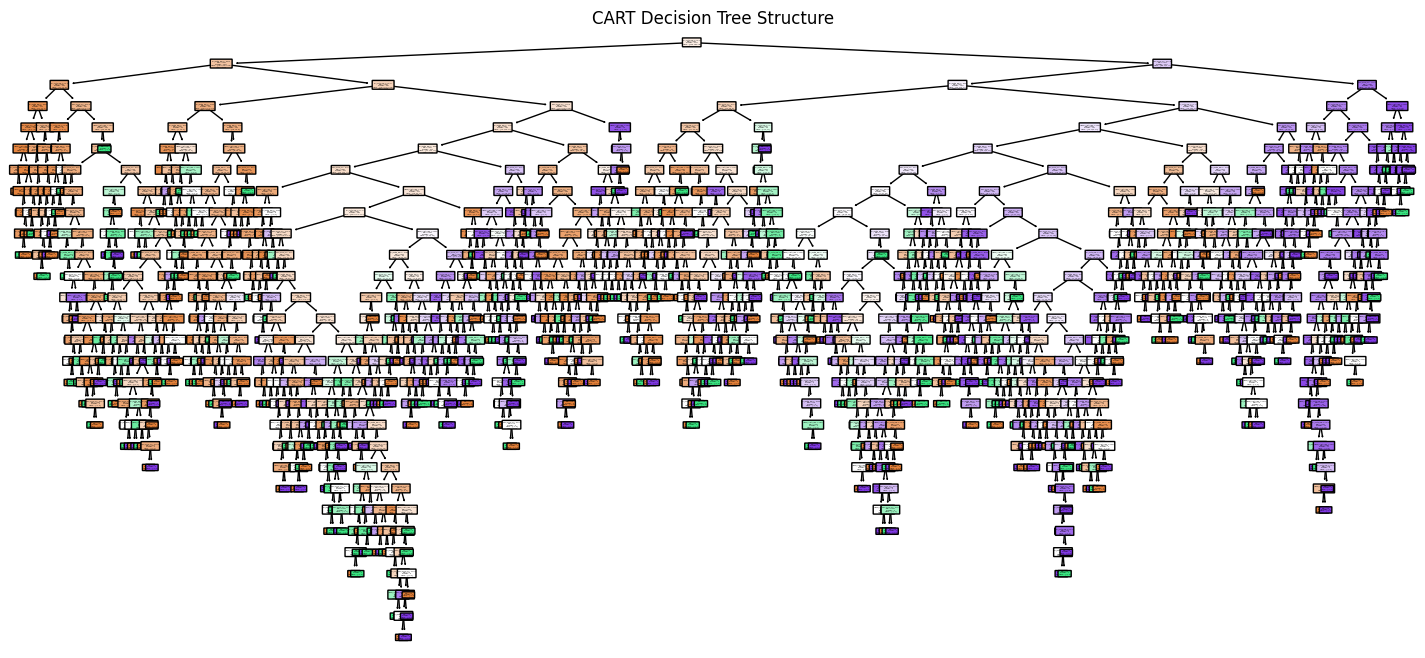

<Figure size 1000x600 with 0 Axes>

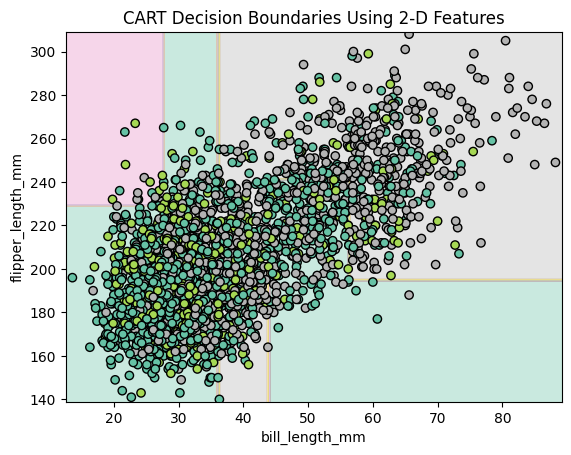

In [ ]:
# Task 6: Visualize Decision Tree & Decision Boundary

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
import pandas as pd

# 1. Visualize the full decision tree
plt.figure(figsize=(18, 8))
plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True
)
plt.title("CART Decision Tree Structure")
plt.show()

# 2. Select 2-D features
length_col = "culmen_length_mm" if "culmen_length_mm" in df.columns else "bill_length_mm"
depth_features = [length_col, "flipper_length_mm"]

X_2d = df[depth_features]
y_2d = le.transform(df["species"])

# Split 2-D data
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y_2d, test_size=0.2, random_state=42, stratify=y_2d
)

# 3. Train decision tree on 2-D features
dt_2d = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)
dt_2d.fit(X2_train, y2_train)

# 4. Plot rectangular decision boundaries
plt.figure(figsize=(10, 6))

DecisionBoundaryDisplay.from_estimator(
    dt_2d,
    X2_train,
    response_method="predict",
    cmap=plt.cm.Set2,
    alpha=0.35,
    xlabel=depth_features[0],
    ylabel=depth_features[1]
)

plt.scatter(
    X2_train[depth_features[0]],
    X2_train[depth_features[1]],
    c=y2_train,
    cmap=plt.cm.Set2,
    edgecolors="black"
)

plt.xlabel(depth_features[0])
plt.ylabel(depth_features[1])
plt.title("CART Decision Boundaries Using 2-D Features")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression Accuracy: 0.5262390670553936


<Figure size 1000x600 with 0 Axes>

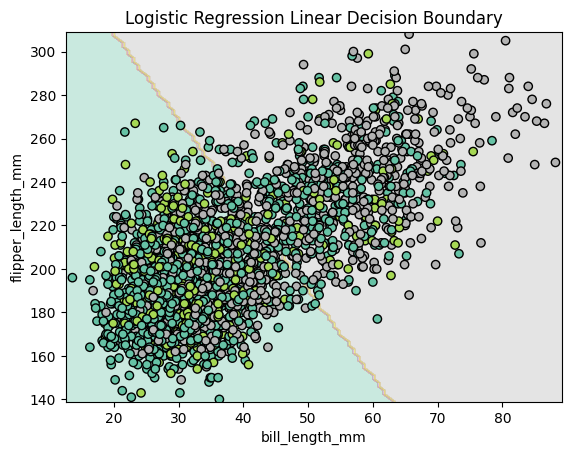

In [ ]:
# Task 7: Logistic Regression Linear Classification Boundary

from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

# Train Logistic Regression using the same 2-D features
lr_2d = LogisticRegression(max_iter=1000)
lr_2d.fit(X2_train, y2_train)

# Predict test data
y2_pred_lr = lr_2d.predict(X2_test)

print("Logistic Regression Accuracy:",
      lr_2d.score(X2_test, y2_test))

# Plot linear decision boundary
plt.figure(figsize=(10, 6))

DecisionBoundaryDisplay.from_estimator(
    lr_2d,
    X2_train,
    response_method="predict",
    cmap=plt.cm.Set2,
    alpha=0.35,
    xlabel=depth_features[0],
    ylabel=depth_features[1]
)

# Plot data points
plt.scatter(
    X2_train[depth_features[0]],
    X2_train[depth_features[1]],
    c=y2_train,
    cmap=plt.cm.Set2,
    edgecolors="black"
)

plt.xlabel(depth_features[0])
plt.ylabel(depth_features[1])
plt.title("Logistic Regression Linear Decision Boundary")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

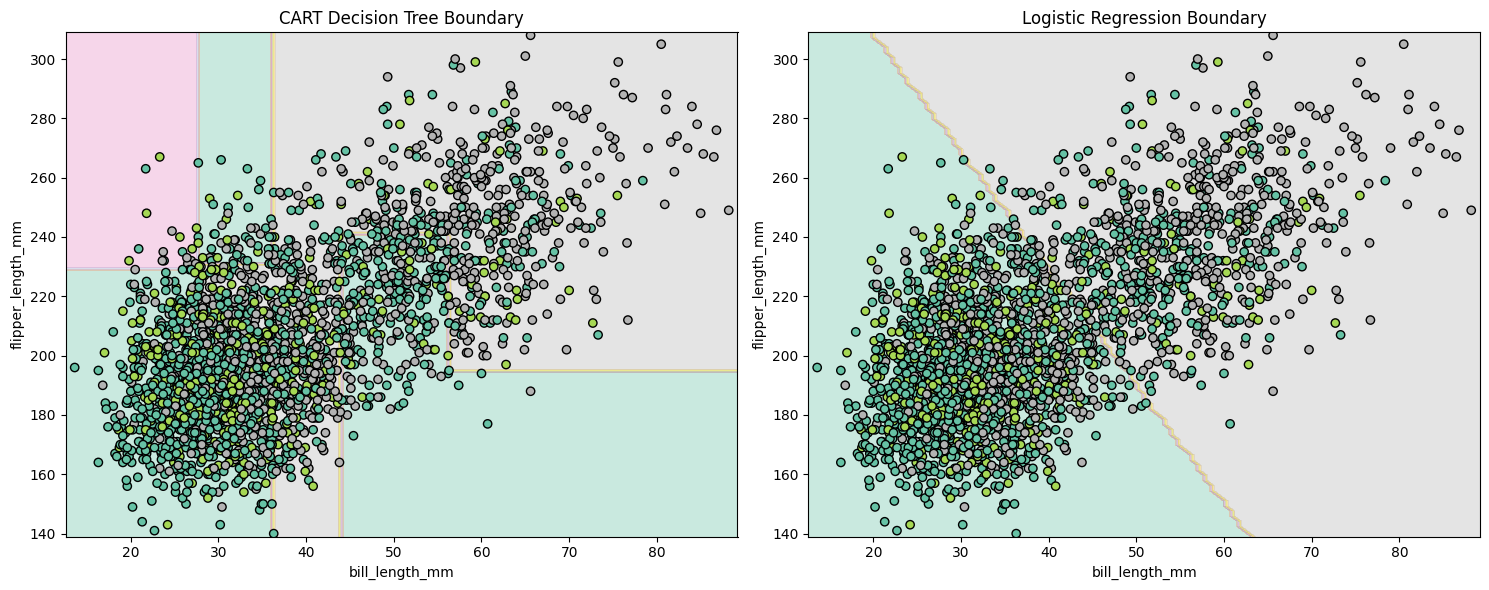

In [ ]:
# Task 8: Compare CART and Logistic Regression Decision Boundaries

import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: CART Decision Tree
DecisionBoundaryDisplay.from_estimator(
    dt_2d,
    X2_train,
    response_method="predict",
    cmap=plt.cm.Set2,
    alpha=0.35,
    ax=axes[0]
)

axes[0].scatter(
    X2_train.iloc[:, 0], X2_train.iloc[:, 1],
    c=y2_train, cmap=plt.cm.Set2, edgecolors="black"
)
axes[0].set_title("CART Decision Tree Boundary")
axes[0].set_xlabel(depth_features[0])
axes[0].set_ylabel(depth_features[1])

# Plot 2: Logistic Regression
DecisionBoundaryDisplay.from_estimator(
    lr_2d,
    X2_train,
    response_method="predict",
    cmap=plt.cm.Set2,
    alpha=0.35,
    ax=axes[1]
)

axes[1].scatter(
    X2_train.iloc[:, 0], X2_train.iloc[:, 1],
    c=y2_train, cmap=plt.cm.Set2, edgecolors="black"
)
axes[1].set_title("Logistic Regression Boundary")
axes[1].set_xlabel(depth_features[0])
axes[1].set_ylabel(depth_features[1])

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

CART Classifier Accuracy: 0.5131195335276968
Logistic Regression Accuracy: 0.5262390670553936


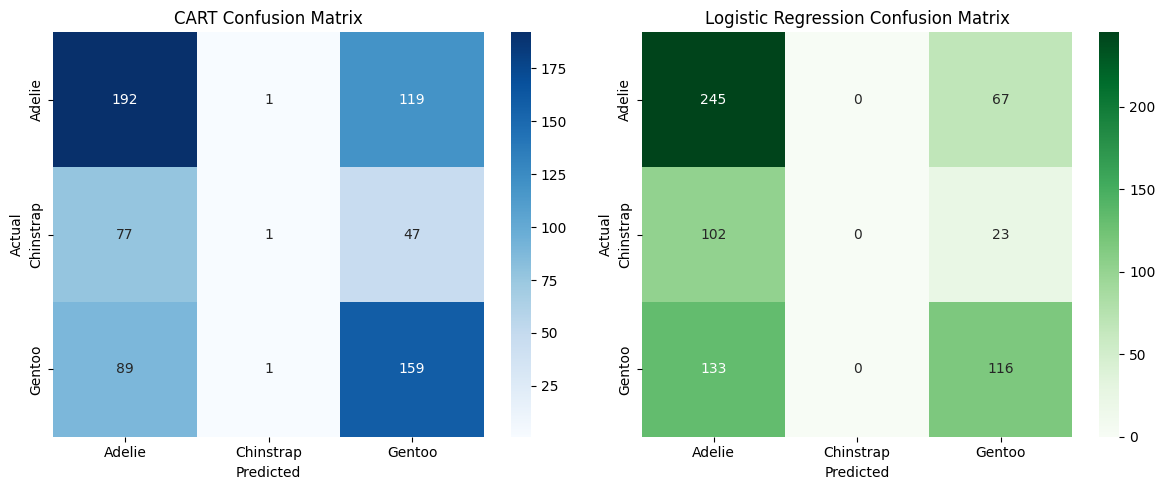


CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.54      0.62      0.57       312
   Chinstrap       0.33      0.01      0.02       125
      Gentoo       0.49      0.64      0.55       249

    accuracy                           0.51       686
   macro avg       0.45      0.42      0.38       686
weighted avg       0.48      0.51      0.46       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686



In [ ]:
# Task 9: Compare Performance of CART and Logistic Regression

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions using the same 2-D test data
y_pred_cart = dt_2d.predict(X2_test)
y_pred_lr = lr_2d.predict(X2_test)

# Compare accuracy
print("CART Classifier Accuracy:",
      accuracy_score(y2_test, y_pred_cart))

print("Logistic Regression Accuracy:",
      accuracy_score(y2_test, y_pred_lr))

# Confusion matrices
cm_cart = confusion_matrix(y2_test, y_pred_cart)
cm_lr = confusion_matrix(y2_test, y_pred_lr)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm_cart, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_,
            ax=axes[0])
axes[0].set_title("CART Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Greens",
            xticklabels=le.classes_, yticklabels=le.classes_,
            ax=axes[1])
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Classification reports
print("\nCART Classification Report:")
print(classification_report(
    y2_test, y_pred_cart, target_names=le.classes_, zero_division=0
))

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y2_test, y_pred_lr, target_names=le.classes_, zero_division=0
))

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.